# phase 7 — จูน v8: ก่อนจูน vs หลังจูน

**สรุป:** ทำภาษามือเร็วแล้วคำหายน้อยลง (WER 2× 0.386 → 0.372) · คำเกินในคลิปจริงลดลง (0.700 → 0.600) · ระบบยืนยันคำได้เกือบ 2 เท่าโดยความแม่นเท่าเดิม · ที่เหลือเท่าเดิม

เปลี่ยน 3 ค่าใน `models/spotting.json` (ไม่ได้เทรนโมเดลใหม่):

| ค่า | ก่อน → หลัง | แก้ปัญหาอะไร |
|---|---|---|
| `post.p_sign_min` | 0.65 → 0.55 | ทำเร็วแล้ว tagger ไม่มั่นใจ ตัวกรองท้ายเลยทิ้งท่าจริง |
| `accept_min` | 0.8 → 0.7 | คำที่คะแนน 0.7–0.8 ถูก 93% แต่ระบบไม่กล้ายืนยัน |
| `post.min_hand_frac` (ใหม่) | – → 0.3 | ระบบตัดท่าตอนกล้องไม่เห็นมือ (เจอตอนเทสกล้องสด) |

ข้อมูล: TSL51 test 126 ประโยค (เลือกค่าบนชุด tune แล้วเปิด test ครั้งเดียว) + วิดีโอจริง · รายละเอียดทุกการทดลอง: `pitty/TUNING_REPORT.md`

## ผลรวม

In [1]:
import sys
sys.path.insert(0, r"C:/Users/ppich/OneDrive/Desktop/tu/yrs4/DSI490/Main_demo/pitty/scripts")
from team_metrics import show
show()

ตัววัด,ชุดทดสอบ,ก่อนจูน,หลังจูน,ผล
WER (ต่ำ = ดี),TSL51 ปกติ (1×),0.440,0.441,เท่าเดิม
,TSL51 เร็ว (2×),0.386,0.372,ดีขึ้น
,data_test (5 คลิป),0.752,0.752,เท่าเดิม
,คลิปที่อัดเอง (5 คลิป),0.700,0.600,ดีขึ้น
,คลิปที่อัดเอง ตัดหัวท้าย (7 คลิป),0.581,0.581,เท่าเดิม
Segment F1 (สูง = ดี),TSL51 ปกติ (1×),0.726,0.728,เท่าเดิม
,TSL51 เร็ว (2×),0.612,0.613,เท่าเดิม
Recall@1 (สูง = ดี),TSL51 ปกติ (1×),0.64,0.64,เท่าเดิม
,TSL51 เร็ว (2×),0.62,0.63,ดีขึ้น
,data_test (5 คลิป),0.32,0.32,เท่าเดิม


* **Recall@1** นับตามลำดับคำ (คำถูก ณ ตำแหน่งนั้น) ไม่ใช่นับว่าคำโผล่ที่ไหนก็ได้ จึงต่ำกว่าตัวเลขแบบเดิม
* **Segment F1** = ขอบเขตท่าทับกับที่มาร์กไว้ ≥ 50% · **คำที่ระบบยืนยัน** = ถูก / จำนวนคำที่ระบบยืนยัน (ไม่ใช่คำทั้งหมด)

## ตัวอย่างจริง

### 1. `p_sign_min` 0.65 → 0.55 — ทำภาษามือเร็ว (2×)
test: ดีขึ้น **7** ประโยค · แย่ลง **0** · คำหายรวม 65 → 47 คำ

**ทำไม:** ตอนทำเร็ว tagger ไม่มั่นใจว่าตรงนั้นเป็นท่า → ตัวกรองท้ายทิ้งท่าจริงไป (ช่องหายไปทั้งช่อง) · ลดเกณฑ์แล้วท่ากลับมา

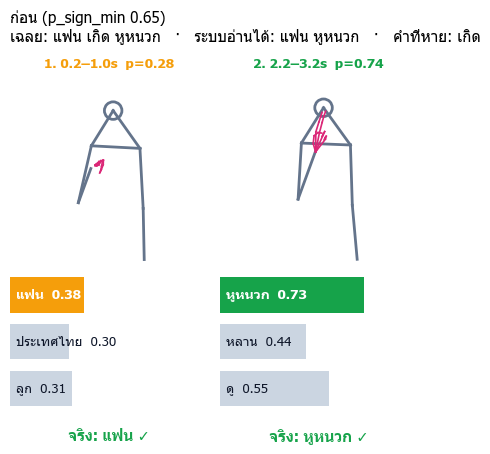

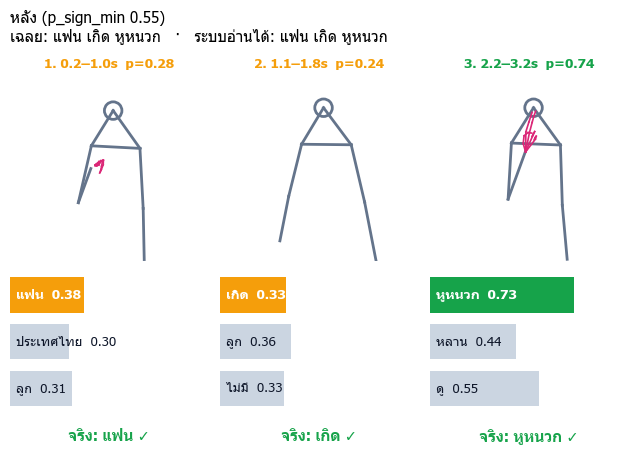

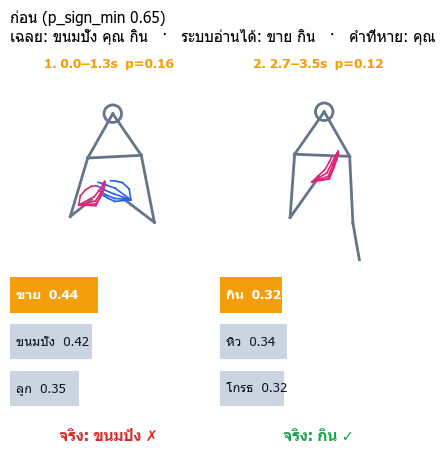

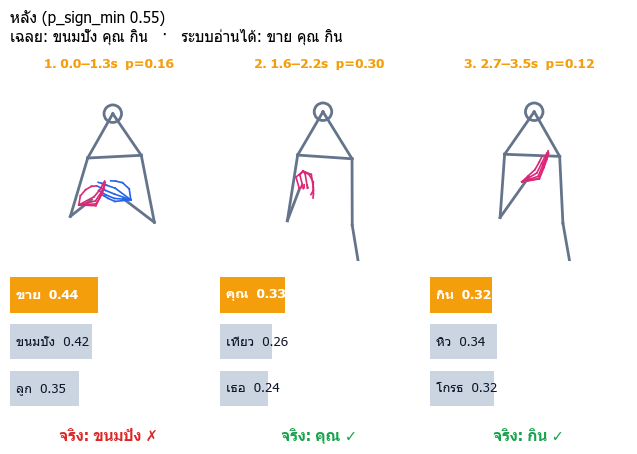

### 2. `accept_min` 0.8 → 0.7 (1×)
คำที่คะแนน 0.7–0.8 มี 61 คำ · **ถูก 57 คำ (93%)** → ยืนยันได้เลย ไม่ต้องขึ้น [?]

**ทำไม:** คำที่คะแนน 0.7–0.8 ถูกบ่อยพอๆ กับคำที่เกิน 0.8 · ระบบไม่ได้ทายต่างไปเลย แค่ช่องที่เคยเป็นสีส้มกลายเป็นสีเขียว

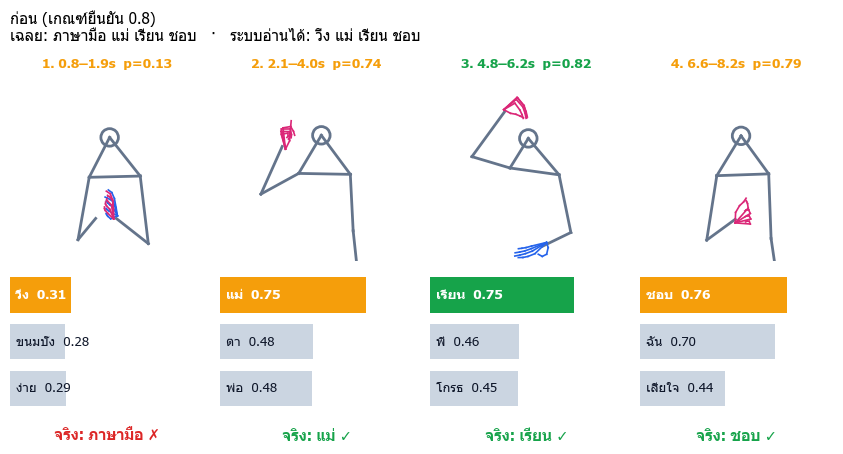

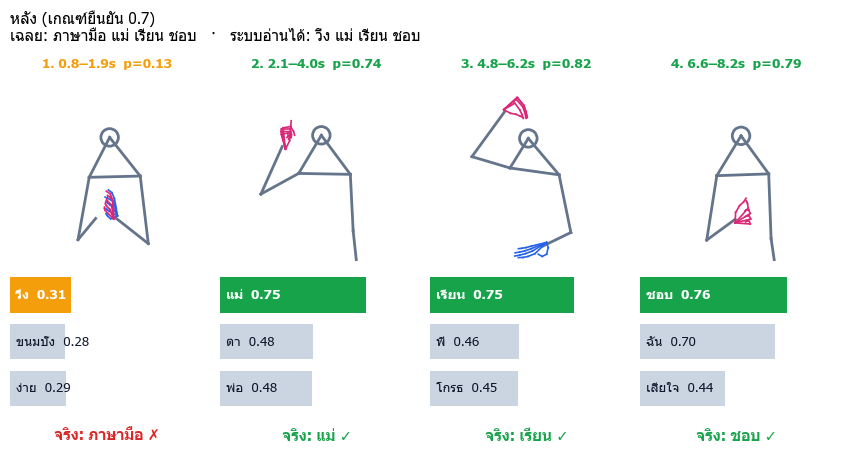

In [2]:
# ตัวอย่างจริงจาก TSL51 test แบบ timeline (เหมือน phase 8 แต่ TSL51 มีแค่จุดร่างกาย → วาดโครงร่างแทนภาพวิดีโอ)
# แต่ละช่อง = ท่าที่ระบบตรวจเจอ 1 ท่า · p = P(ถูก) (🟩 ยืนยัน · 🟧 ไม่แน่ใจ · 🟥 ไม่รู้จัก) · 3 คำที่ใกล้ที่สุด · ล่างสุด = คำจริง ✓/✗
import json, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path(r"C:/Users/ppich/OneDrive/Desktop/tu/yrs4/DSI490/Main_demo"); sys.path.insert(0, str(ROOT / "pitty/scripts"))
from sentence_strip import strip
D = ROOT / "cache/pitty_tune"
load = lambda f: {r["clip"]: r for r in json.loads((D / f).read_text(encoding="utf-8"))["results"]}

def compare(before, after, speed, thr_b, thr_a, lab_b, lab_a, clip):
    for r, thr, lab in ((before[clip], thr_b, lab_b), (after[clip], thr_a, lab_a)):
        fig = strip(r, speed, thr, lab); plt.show()

# ---------- 1. p_sign_min 0.65 → 0.55 — ทำภาษามือเร็ว (2×) · ใช้เกณฑ์ยืนยัน 0.7 ทั้งคู่ เพื่อให้เห็นผลของ p_sign_min อย่างเดียว
A, B = load("pairs_test_x2.0.json"), load("del/ps55_test_x2.json")
better = sum(B[k]["WER"] < A[k]["WER"] for k in A); worse = sum(B[k]["WER"] > A[k]["WER"] for k in A)
display(Markdown(f"### 1. `p_sign_min` 0.65 → 0.55 — ทำภาษามือเร็ว (2×)\n"
                 f"test: ดีขึ้น **{better}** ประโยค · แย่ลง **{worse}** · คำหายรวม 65 → 47 คำ\n\n"
                 "**ทำไม:** ตอนทำเร็ว tagger ไม่มั่นใจว่าตรงนั้นเป็นท่า → ตัวกรองท้ายทิ้งท่าจริงไป (ช่องหายไปทั้งช่อง) · ลดเกณฑ์แล้วท่ากลับมา"))
for clip in ["t51s:แฟน_var_1__เกิด_var_2__หูหนวก_var_2_no_space_1", "t51s:ขนมปัง_var_1__คุณ_var_1__กิน_var_1_no_space_2"]:
    compare(A, B, 2.0, 0.7, 0.7, "ก่อน (p_sign_min 0.65)", "หลัง (p_sign_min 0.55)", clip)

# ---------- 2. accept_min 0.8 → 0.7 (1×) · ผลเดียวกัน เปลี่ยนแค่เกณฑ์ยืนยัน → ดูสีที่เปลี่ยน
B1 = load("del/ps55_test_x1.json")
band = [(w in set(r["ref"])) for r in B1.values() for w, p in zip(r["top1"], r["p"]) if 0.7 <= p < 0.8]
display(Markdown(f"### 2. `accept_min` 0.8 → 0.7 (1×)\n"
                 f"คำที่คะแนน 0.7–0.8 มี {len(band)} คำ · **ถูก {sum(band)} คำ ({np.mean(band):.0%})** → ยืนยันได้เลย ไม่ต้องขึ้น [?]\n\n"
                 "**ทำไม:** คำที่คะแนน 0.7–0.8 ถูกบ่อยพอๆ กับคำที่เกิน 0.8 · ระบบไม่ได้ทายต่างไปเลย แค่ช่องที่เคยเป็นสีส้มกลายเป็นสีเขียว"))
compare(B1, B1, 1.0, 0.8, 0.7, "ก่อน (เกณฑ์ยืนยัน 0.8)", "หลัง (เกณฑ์ยืนยัน 0.7)", "t51s:ภาษามือ_var_1__แม่_var_1__เรียน_var_1__ชอบ_var_1_no_space_2")


## ฟีเจอร์ "ท่าของฉัน" คืออะไร และรู้ได้ยังไงว่าดีขึ้น

**ใช้งานยังไง (มีในเว็บอยู่แล้ว):**
1. ผู้ใช้ทำภาษามือ → ระบบแสดงคำบนการ์ดผลลัพธ์
2. ผู้ใช้**แตะคำ** → กดยืนยันว่าถูก หรือพิมพ์/เลือกคำที่ถูก → กด **บันทึก**
3. เว็บเก็บ "ลายท่า" ของช่วงนั้น (ตัวเลข 768 ตัวจาก encoder) ไว้ในเบราว์เซอร์ของผู้ใช้ (คำละไม่เกิน 3 ตัวอย่าง — ตัวใหม่แทนตัวเก่าสุด) — มุมจอขึ้น "ท่าของฉัน: N คำ"
4. ครั้งต่อไปเว็บส่งลายท่าเหล่านี้ไปด้วย → server เฉลี่ยเป็น 1 ต้นแบบต่อคำ แล้ว**เพิ่มเข้า bank เฉพาะคำขอของผู้ใช้คนนี้** → ท่าแบบที่ผู้ใช้คนนี้ทำ ถูกจับคู่ได้ง่ายขึ้น
5. **ไม่ได้เทรนโมเดลใหม่** · โมเดลและ bank กลางไม่เปลี่ยน · ผู้ใช้คนอื่นไม่ได้รับผล

**วัดยังไง:** จำลองผู้ใช้คนเดียวใช้งาน 2 รอบ — รอบแรก (ประโยคชุด **tune**) แก้เฉพาะคำที่ระบบทายผิด คำละ 2 ตัวอย่าง · รอบสอง (ประโยคชุด **test** ที่ไม่เคยเห็น) วัด WER เทียบกับตอนไม่สอน


คำที่ 'ผู้ใช้' สอน (16 คำ, คำละ 2 ตัวอย่างจากประโยคชุด tune): เที่ยว · น้อง · ขนมปัง · ยาย · กิน · แฟน · ขอโทษ · ข้าว · ไป · คุณ · อะไร · ชื่อ · เกิด · ที่ไหน · ภาษามือ · ชอบ


ความเร็ว,WER ไม่สอน,WER หลังสอน,ประโยคดีขึ้น / แย่ลง (จาก 126)
1×,0.441,0.160,89 / 2
2×,0.369,0.181,69 / 5


**ตัวอย่าง (1×):** ประโยคใหม่ที่ไม่เคยใช้สอน — ท่าเดิมทุกอย่าง ต่างกันแค่ bank มีท่าของผู้ใช้คนนี้เพิ่ม

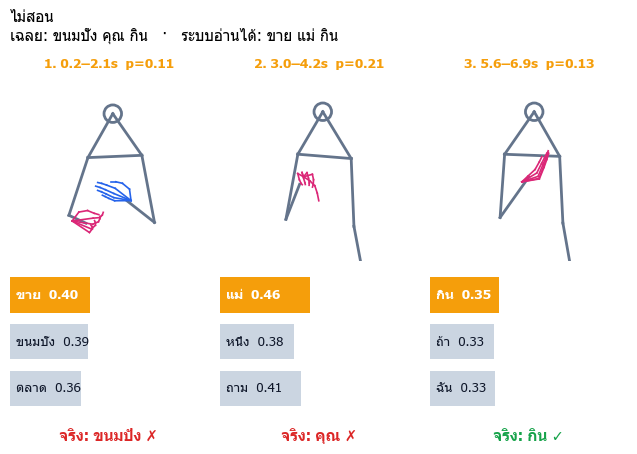

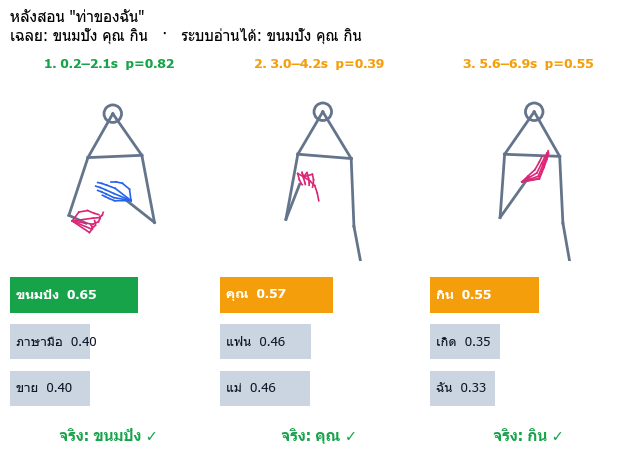

ข้อควรระวัง: TSL51 = คนทำท่าคนเดียว ห้อง/กล้องเดียวกันทั้ง tune และ test → นี่คือเพดานบน · ต้องยืนยันด้วยคลิปที่อัดเอง (รอบแรกสอน รอบสองวัด)


In [3]:
# "ท่าของฉัน": จำลองผู้ใช้สอนท่าบนประโยคชุด tune แล้ววัดกับประโยคชุด test (ไม่ได้รันโมเดลใหม่)
import json, collections, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path(r"C:/Users/ppich/OneDrive/Desktop/tu/yrs4/DSI490/Main_demo"); sys.path.insert(0, str(ROOT / "pitty/scripts"))
from sentence_strip import strip
D = ROOT / "cache/pitty_tune"
load = lambda f: {r["clip"]: r for r in json.loads((D / f).read_text(encoding="utf-8"))["results"]}

taught = collections.Counter(np.load(D / "pm_bank_wrong2.npz", allow_pickle=True)["w"].tolist())
print(f"คำที่ 'ผู้ใช้' สอน ({len(taught)} คำ, คำละ 2 ตัวอย่างจากประโยคชุด tune):", " · ".join(taught))
rows = []
for sp in ("1", "2"):
    A, B = load(f"del/ps55_test_x{sp}.json"), load(f"tech/T_pm_x{sp}.json")
    d = np.array([B[k]["WER"] - A[k]["WER"] for k in A])
    rows.append((f"{sp}×", f"{np.mean([r['WER'] for r in A.values()]):.3f}", f"{np.mean([r['WER'] for r in B.values()]):.3f}",
                 f"{int((d < 0).sum())} / {int((d > 0).sum())}"))
display(pd.DataFrame(rows, columns=["ความเร็ว", "WER ไม่สอน", "WER หลังสอน", "ประโยคดีขึ้น / แย่ลง (จาก 126)"]).style.hide(axis="index"))

display(Markdown("**ตัวอย่าง (1×):** ประโยคใหม่ที่ไม่เคยใช้สอน — ท่าเดิมทุกอย่าง ต่างกันแค่ bank มีท่าของผู้ใช้คนนี้เพิ่ม"))
A, B = load("del/ps55_test_x1.json"), load("tech/T_pm_x1.json")
for r, lab in ((A["t51s:ขนมปัง_var_1__คุณ_var_1__กิน_var_1_no_space_2"], "ไม่สอน"), (B["t51s:ขนมปัง_var_1__คุณ_var_1__กิน_var_1_no_space_2"], "หลังสอน \"ท่าของฉัน\"")):
    strip(r, 1.0, 0.7, lab); plt.show()
print("ข้อควรระวัง: TSL51 = คนทำท่าคนเดียว ห้อง/กล้องเดียวกันทั้ง tune และ test → นี่คือเพดานบน · ต้องยืนยันด้วยคลิปที่อัดเอง (รอบแรกสอน รอบสองวัด)")
